## **Business Understanding**
- Purpose of this is to narrow down and talk about the problem statement

The business currently lacks sufficient insight into how different customers behave in terms of spending. Although it collects customer information such as age, gender, annual income, and spending scores, it does not fully understand the relationships between these characteristics.

This makes it difficult to:
- Identify high-value customers.
- Understand customers with high income but low spending.
- Identify customers who spend frequently or have high spending scores.
- Develop targeted promotional campaigns.
- Allocate marketing resources effectively.

Source:
- [Mall Customers Dataset from Kaggle](https://www.kaggle.com/datasets/amisha0528/mall-customers-dataset)

#### **Import Libraries**

In [3]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

#### **Load Data**

Pandas converts the data to be read into either of 2: 
    - Series (1D dataset)
    - DataFrame ( 2D dataset)

In [4]:
df = pd.read_csv("data/Mall_Customers.csv")

## **Data Understanding**

- shape(dimensions)
- duplicates
- missing values
- data types
- describe (MCTs and MoVs)


shape

In [5]:
df.shape # returns a tuple composed of rows and columns respectively

rows, columns = df.shape
output = f"The data has {rows} records and {columns} features"
print(output)

The data has 200 records and 5 features


In [6]:
features = df.columns
features

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [7]:
df.Age 

0      19
1      21
2      20
3      23
4      31
       ..
195    35
196    45
197    32
198    32
199    30
Name: Age, Length: 200, dtype: int64

In [8]:
df["Age"]

0      19
1      21
2      20
3      23
4      31
       ..
195    35
196    45
197    32
198    32
199    30
Name: Age, Length: 200, dtype: int64

In [9]:
df[features[2]]

0      19
1      21
2      20
3      23
4      31
       ..
195    35
196    45
197    32
198    32
199    30
Name: Age, Length: 200, dtype: int64

Data quality:
    - missing values (evaluate missingness of data) [investigating 'missingness' in data](https://www.datacamp.com/tutorial/techniques-to-handle-missing-data-values)
    - duplicate

In [10]:
df.duplicated().sum()*100/ len(df) # returns % duplicates in data percentage of missing values

np.float64(0.0)

In [11]:
df.isna().sum()*100/len(df) # returns % missing values per column blank spaces will be identified or marked as NaN

CustomerID                0.0
Genre                     0.0
Age                       0.0
Annual Income (k$)        0.0
Spending Score (1-100)    0.0
dtype: float64

checking data types

In [12]:
df.dtypes

CustomerID                int64
Genre                       str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


**Descriptive Stats**
- Measures of Central Tendency (MCTs): This is a single number that describes our entire data. Types: Mean | Median | Mode

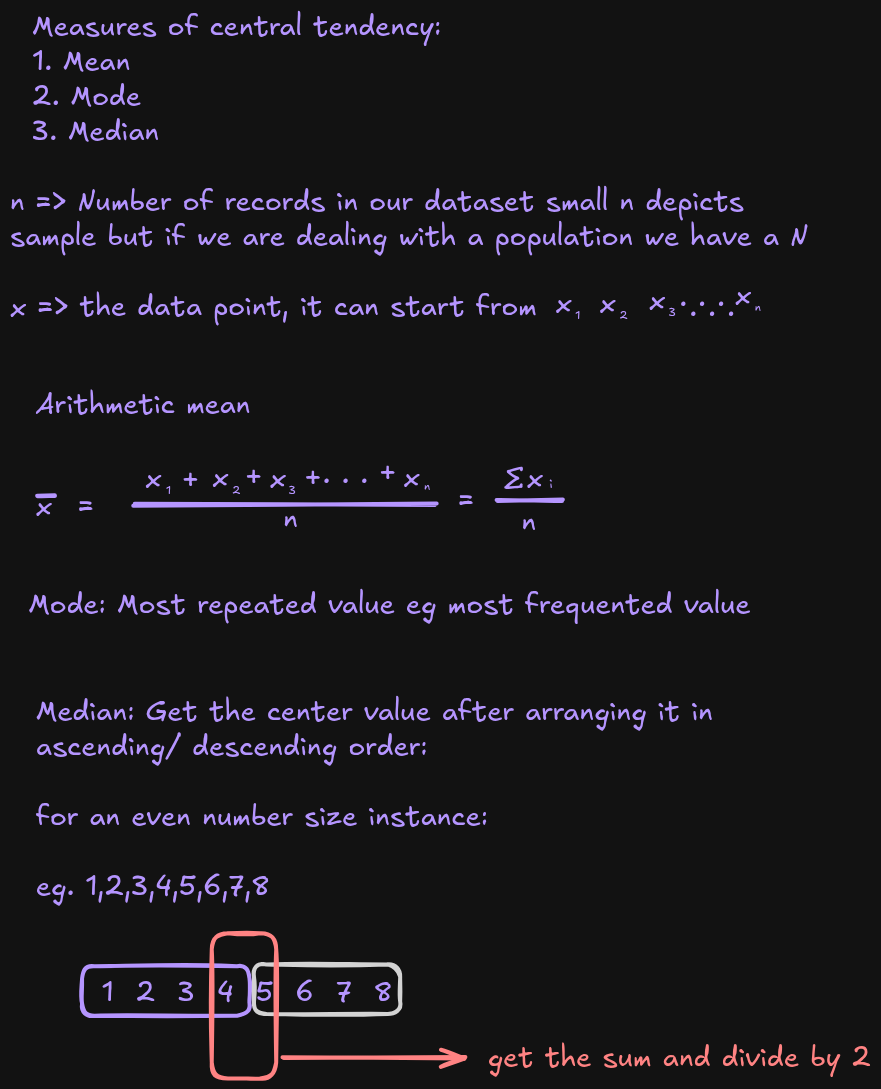

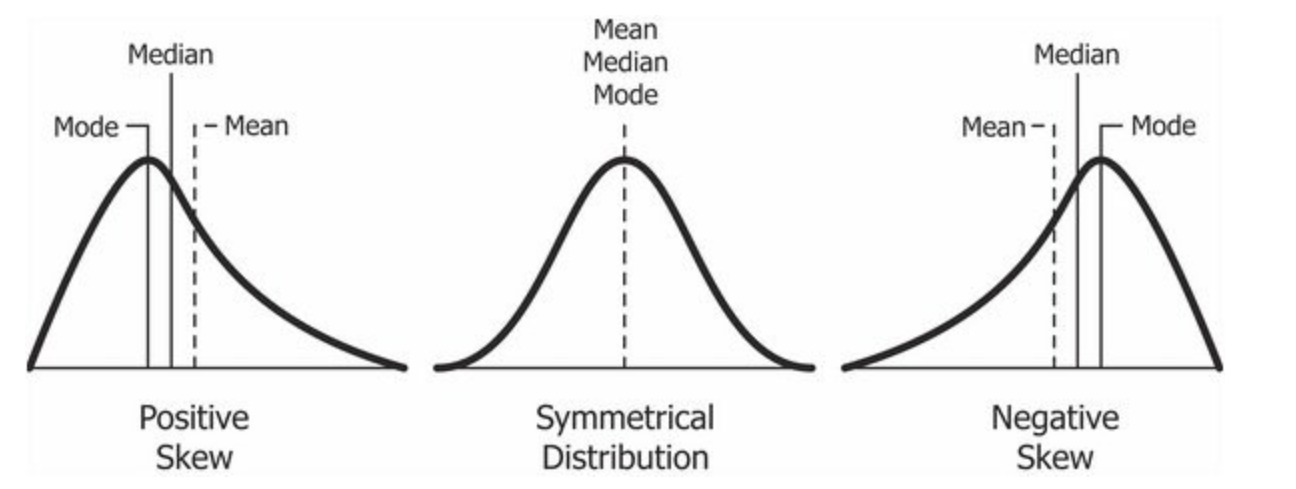

In [14]:
df["Age"].mean()

np.float64(38.85)

In [15]:
df["Age"].mode()

0    32
Name: Age, dtype: int64

In [16]:
df["Age"].median()

np.float64(36.0)

In [17]:
df.dtypes

CustomerID                int64
Genre                       str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

In [18]:
# #  get column
# # get median, mode, mean

# for feature in features:
#     print(f"MEAN: {df[feature].mean()}")
#     print(f"MODE: {df[feature].mode()}")
#     print(f"MEDIAN: {df[feature].median()}")
#     print("="*100)

# # the above returns an error since the data columns are not all quantitative


In [19]:
df.describe() # gives us a statistical summary of the quantitative data columns

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [61]:
df["Age"].describe()

count    200.000000
mean      38.850000
std       13.969007
min       18.000000
25%       28.750000
50%       36.000000
75%       49.000000
max       70.000000
Name: Age, dtype: float64

In [62]:
df["Annual Income (k$)"].describe()

count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Annual Income (k$), dtype: float64

In [20]:
df.describe(include="object") # gives us a statistical summary of the qualitative data columns

/tmp/ipykernel_12958/3275395787.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") # gives us a statistical summary of the qualitative data columns


,Genre
count,200
unique,2
top,Female
freq,112


[plotting distributions](https://seaborn.pydata.org/tutorial/distributions.html)

In [21]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [22]:
annual_income_df = df["Annual Income (k$)"]
annual_income_df

0       15
1       15
2       16
3       16
4       17
      ... 
195    120
196    126
197    126
198    137
199    137
Name: Annual Income (k$), Length: 200, dtype: int64

In [23]:
annual_income_df.describe()

count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Annual Income (k$), dtype: float64

In [44]:
annual_income_df.mode().sum()/2

np.float64(66.0)

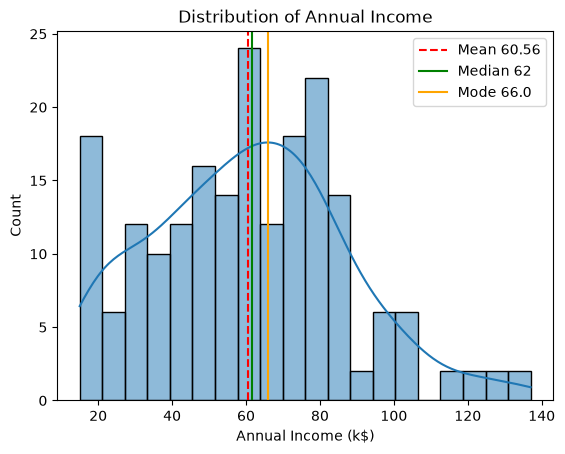

In [51]:
sns.histplot(annual_income_df, kde=True,  bins=20)
plt.axvline(annual_income_df.mean(), color="red", linestyle="--", label=f"Mean {annual_income_df.mean():.2f}")
plt.axvline(annual_income_df.median(), color="green", linestyle="-", label=f"Median {annual_income_df.median():.0f}")
plt.axvline(annual_income_df.mode().sum()/2, color="orange", linestyle="-", label=f"Mode {annual_income_df.mode().sum()/2}")
plt.legend()
plt.title("Distribution of Annual Income")
plt.show()

In [54]:
spending_score_df = df["Spending Score (1-100)"]
spending_score_df.describe()

count    200.000000
mean      50.200000
std       25.823522
min        1.000000
25%       34.750000
50%       50.000000
75%       73.000000
max       99.000000
Name: Spending Score (1-100), dtype: float64

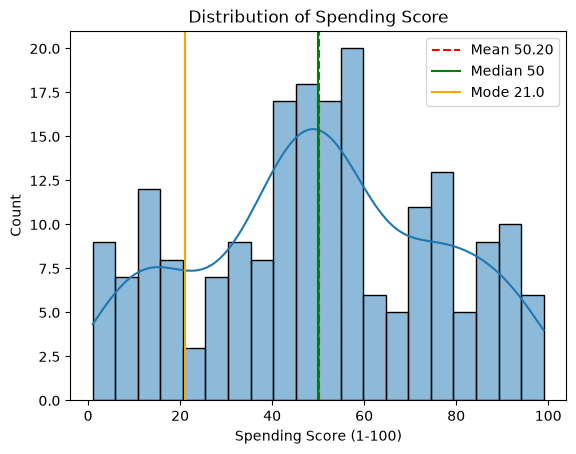

In [57]:
sns.histplot(spending_score_df, kde=True,  bins=20)
plt.axvline(spending_score_df.mean(), color="red", linestyle="--", label=f"Mean {spending_score_df.mean():.2f}")
plt.axvline(spending_score_df.median(), color="green", linestyle="-", label=f"Median {spending_score_df.median():.0f}")
plt.axvline(spending_score_df.mode().sum()/2, color="orange", linestyle="-", label=f"Mode {spending_score_df.mode().sum()/2}")
plt.legend()
plt.title("Distribution of Spending Score")
plt.show()

In [59]:
age_df = df["Age"]
age_df.describe()


count    200.000000
mean      38.850000
std       13.969007
min       18.000000
25%       28.750000
50%       36.000000
75%       49.000000
max       70.000000
Name: Age, dtype: float64

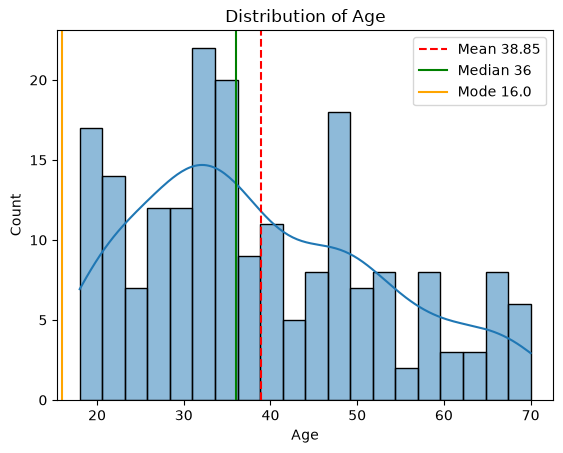

In [60]:

sns.histplot(age_df, kde=True,  bins=20)
plt.axvline(age_df.mean(), color="red", linestyle="--", label=f"Mean {age_df.mean():.2f}")
plt.axvline(age_df.median(), color="green", linestyle="-", label=f"Median {age_df.median():.0f}")
plt.axvline(age_df.mode().sum()/2, color="orange", linestyle="-", label=f"Mode {age_df.mode().sum()/2}")
plt.legend()
plt.title("Distribution of Age")
plt.show()

#### **Insights**

- The data has 200 records and 5 features
- The data has 0% missing value & 0% duplicates
- The data has 4 numerical(Quantitative) columns and 1 categorical(Qualitative) column

### Inforgraph Summary

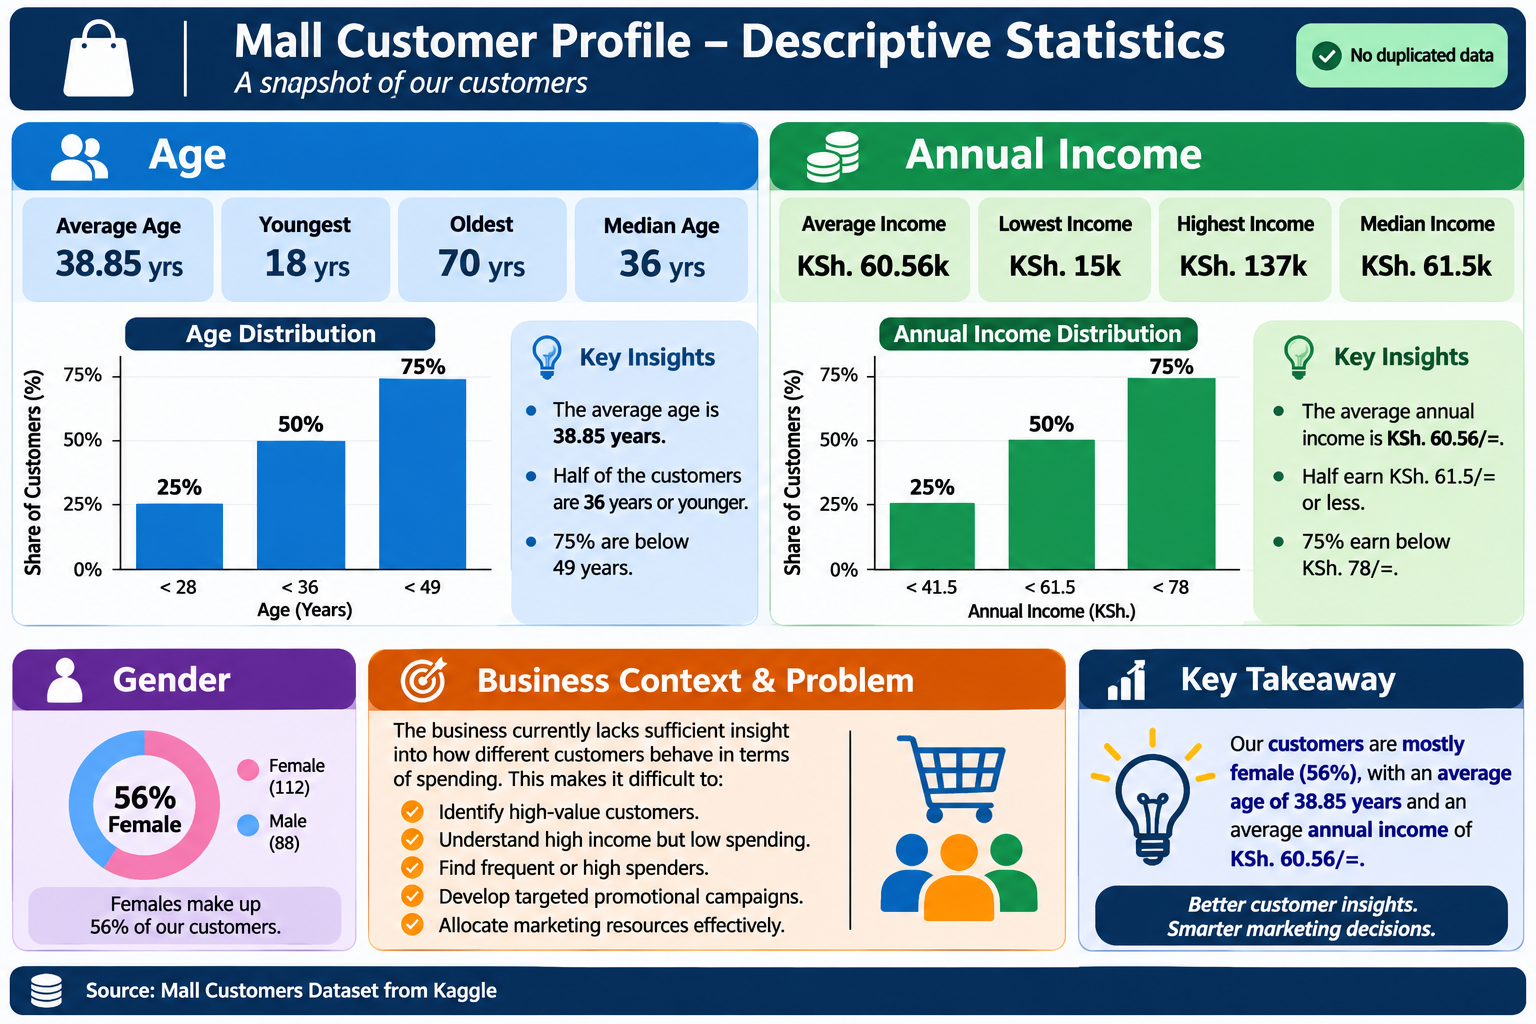